In [1]:
from tqdm import tqdm
from astropy.table import Table
import numpy as np
import h5py
import pandas as pd
import data
import matplotlib.pyplot as plt
import sample
from scipy import stats
from multicam.multicam import MultiCAM


TNG_H = 0.6774

In [2]:
### Import cache file hydro ###
hydro_path = 'data/cache_files/hydro_color_tree_no_subhaloflag_check_data.csv'
hydro_data = pd.read_csv(hydro_path, usecols=['SubhaloFlag', 'SubhaloMass', 'StellarMass', 'x', 'y', 'z',
                                              'logStellarMass', 'logSubhaloMass', 'g-i',
                                              'vpeak', 'a12'])
print("\nHydro Table Length:")
print(len(hydro_data))


Hydro Table Length:
101431


**Note:** Corresponds to data with no stellar mass particle minimum (1.4 * 10^8 minimum on Stellar Mass for hydro catalog what we decided for cam), the data does also not include the check subhalo flag cut

In [3]:
# Define unmatched params
a12_unmatched = hydro_data['a12']
vpeak_unmatched = hydro_data['vpeak']
color_unmatched = hydro_data['g-i']
stellarmass_unmatched = hydro_data['StellarMass']
subhalomass_unmatched = hydro_data['SubhaloMass']
subhaloflag = hydro_data['SubhaloFlag']

data = pd.DataFrame({
    'a12': a12_unmatched,
    'vpeak': vpeak_unmatched,
    'color': color_unmatched,
    'StellarMass': stellarmass_unmatched,
    'SubhaloMass': subhalomass_unmatched,
    'SubhaloFlag': subhaloflag
})


match_path = 'data/match_data/matches-trees-tng100.npz'

with open(match_path, 'rb') as fp:
    # file containing matching information
    match_dict = np.load(fp, allow_pickle=True)
    print("matches_bar length: ", len(match_dict['matches_bar']))

    # boolean array corresponding to whether each halo in the hydro data is matched or not
    match_hydro = match_dict['matches_bar']

# get mask of matched quantities
mask_hydro_match = match_hydro != -1 # "-1" corresponds to unmatched haloes


# matched subsets
data['a12_matched']         = a12_unmatched[mask_hydro_match]
data['vpeak_matched']       = vpeak_unmatched[mask_hydro_match]
data['color_matched']       = color_unmatched[mask_hydro_match]
data['stellarmass_matched'] = stellarmass_unmatched[mask_hydro_match]
data['subhalomass_matched'] = subhalomass_unmatched[mask_hydro_match]

print("Data length w/o cuts", len(data))

data = data[data['SubhaloFlag'] == 1]
print("Data length w/ subhaloflag cut", len(data))

data = data[data['StellarMass'] >= 1.4e8]
print("Data length w/ min number stellar mass particles", len(data))

matches_bar length:  101431
Data length w/o cuts 101431
Data length w/ subhaloflag cut 101364
Data length w/ min number stellar mass particles 25437


Unmatched corner plot


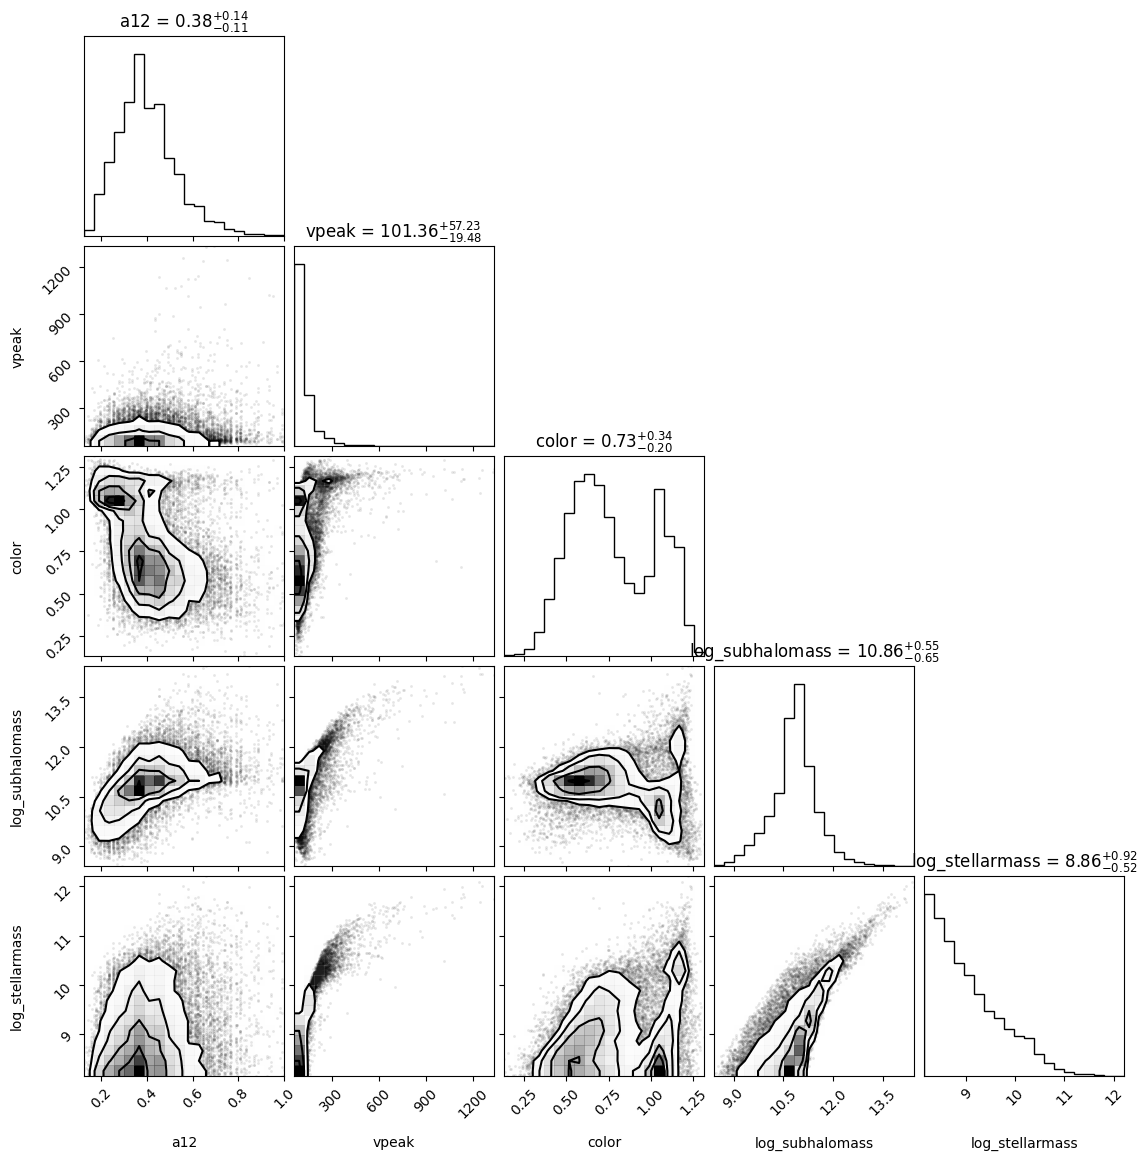

In [4]:
import corner
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

print("Unmatched corner plot")

# Stack for corner plot
unmatched_data = np.vstack([data['a12'], 
                            data['vpeak'],
                            data['color'],
                            np.log10(data['SubhaloMass']),
                            np.log10(data['StellarMass'])]).T

# Create the corner plot
figure = corner.corner(
    unmatched_data,
    labels=["a12", "vpeak", "color", "log_subhalomass", "log_stellarmass"],
    show_titles=True
)

plt.show()
figure.savefig("corner_plot_unmatched.png", dpi=300, bbox_inches="tight")

In [5]:
for col in ['a12_matched','vpeak_matched','color_matched',
            'subhalomass_matched','stellarmass_matched']:
    print(col, len(data[col]))

a12_matched 25437
vpeak_matched 25437
color_matched 25437
subhalomass_matched 25437
stellarmass_matched 25437


Matched corner plot


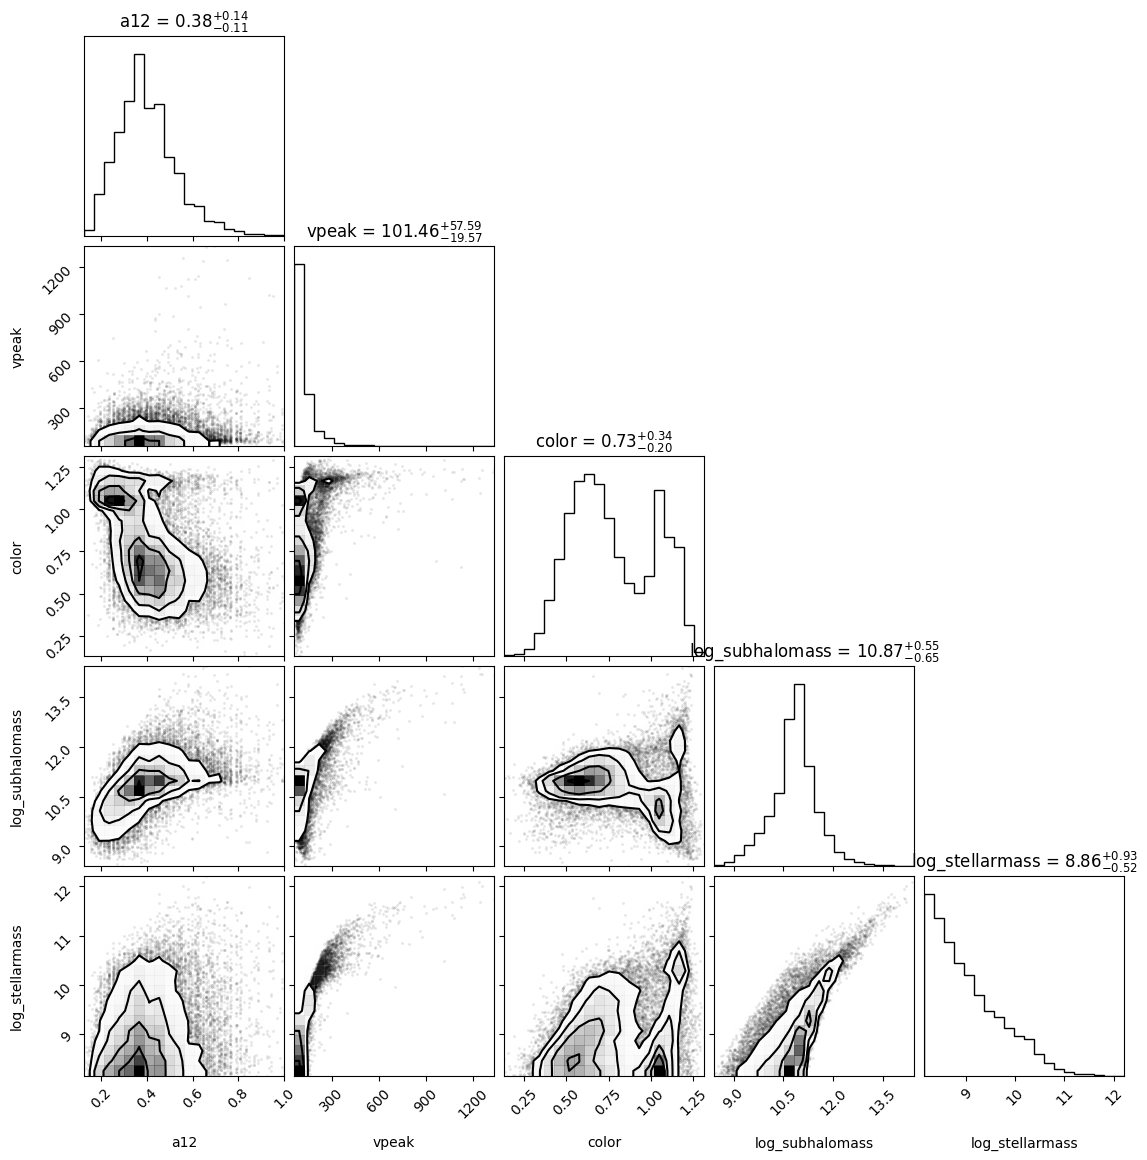

In [6]:
import corner
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

data = data[data['subhalomass_matched'] > 0]
data = data[data['stellarmass_matched'] > 0]

print("Matched corner plot")

# Stack for corner plot
matched_data = np.vstack([data['a12_matched'], 
                            data['vpeak_matched'],
                            data['color_matched'],
                            np.log10(data['subhalomass_matched']),
                            np.log10(data['stellarmass_matched'])]).T

# Create the corner plot
figure = corner.corner(
    matched_data,
    labels=["a12", "vpeak", "color", "log_subhalomass", "log_stellarmass"],
    show_titles=True
)

plt.show()
figure.savefig("corner_plot_matched.png", dpi=300, bbox_inches="tight")

In [7]:
### Import cache file dmo ###
dmo_path = 'data/cache_files/dmo_tree_data.csv'
dmo_tree_data = pd.read_csv(dmo_path, usecols=['SubhaloMass', 'logSubhaloMass', 
                                              'vpeak','mpeak_pre', 'mpeak',
                                              'x', 'y', 'z', 'a12'])
print("\nDMO Table Length:")
print(len(dmo_tree_data))




DMO Table Length:
533674


In [8]:
# Define unmatched params
a12_unmatched = dmo_tree_data['a12']
vpeak_unmatched = dmo_tree_data['vpeak']
mpeak_unmatched = dmo_tree_data['mpeak']
mpeak_pre_unmatched = dmo_tree_data['mpeak_pre']
subhalomass_unmatched = dmo_tree_data['SubhaloMass']

dmo_data = pd.DataFrame({
    'a12': a12_unmatched,
    'vpeak': vpeak_unmatched,
    'mpeak': mpeak_unmatched,
    'mpeak_pre': mpeak_pre_unmatched,
    'SubhaloMass': subhalomass_unmatched,
})


match_path = 'data/match_data/matches-trees-tng100.npz'

with open(match_path, 'rb') as fp:
    # file containing matching information
    match_dict = np.load(fp, allow_pickle=True)
    print("matches_dmo length: ", len(match_dict['matches_dmo']))

    match_dmo = match_dict['matches_dmo']

# get mask of matched quantities
mask_dmo_match = match_dmo != -1 # "-1" corresponds to unmatched haloes


# matched subsets
dmo_data['a12_matched']         = a12_unmatched[mask_dmo_match]
dmo_data['vpeak_matched']       = vpeak_unmatched[mask_dmo_match]
dmo_data['mpeak_matched']       = mpeak_unmatched[mask_dmo_match]
dmo_data['mpeak_pre_matched']       = mpeak_pre_unmatched[mask_dmo_match]
dmo_data['subhalomass_matched'] = subhalomass_unmatched[mask_dmo_match]

print("Data length w/o cuts", len(dmo_data))

# Pick top whatever of DMO and then do SHAM
dmo_data = dmo_data.sort_values('vpeak', ascending=False).head(len(data))
print("\nNew DMO Table Length:")
print(len(dmo_data))

matches_dmo length:  533674
Data length w/o cuts 533674

New DMO Table Length:
23786


Unmatched dmo corner plot


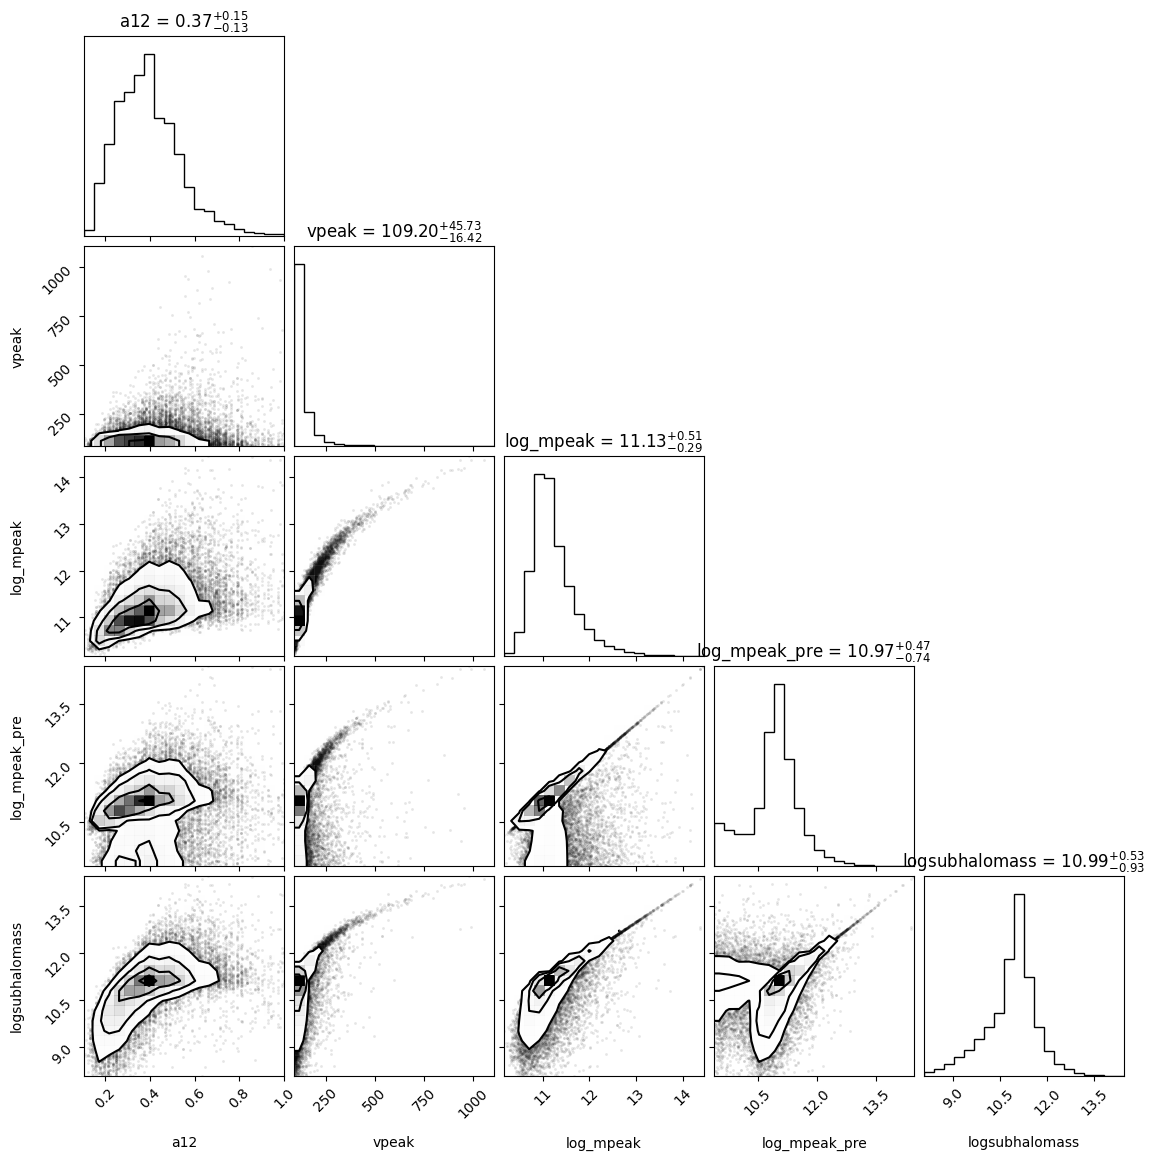

In [9]:
import corner
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

print("Unmatched dmo corner plot")

# Stack for corner plot
unmatched_data = np.vstack([dmo_data['a12'], 
                            dmo_data['vpeak'],
                            np.log10(dmo_data['mpeak']),
                            np.log10(dmo_data['mpeak_pre']),
                            np.log10(dmo_data['SubhaloMass'])]).T

# Create the corner plot
figure = corner.corner(
    unmatched_data,
    labels=["a12", "vpeak", "log_mpeak", "log_mpeak_pre", "logsubhalomass"],
    show_titles=True
)

plt.show()
figure.savefig("corner_plot_dmo_unmatched.png", dpi=300, bbox_inches="tight")

Matched dmo corner plot


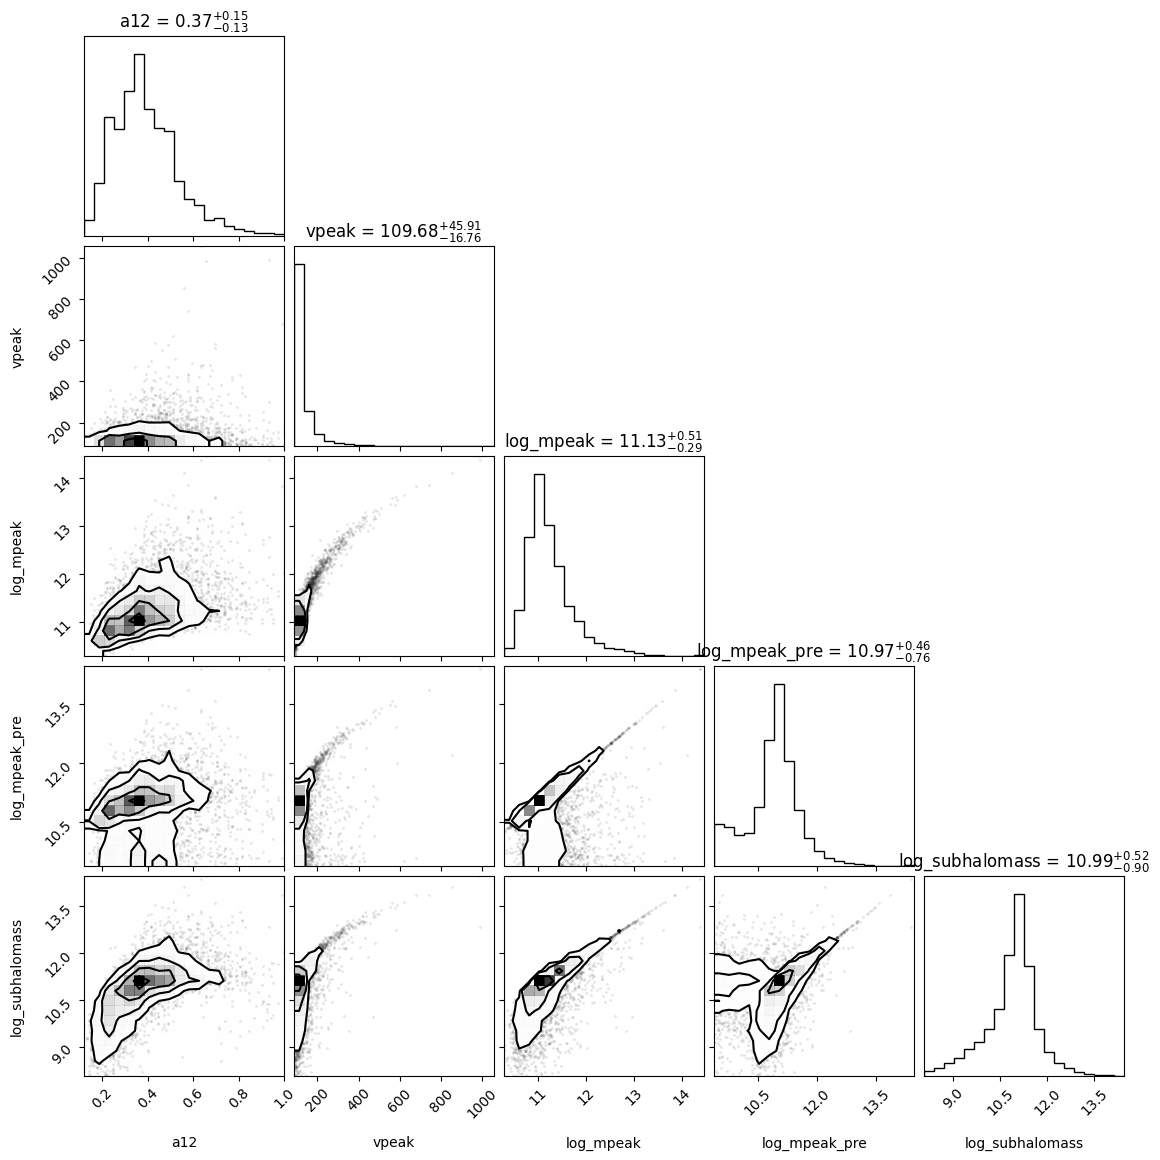

In [10]:
import corner
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np

print("Matched dmo corner plot")
dmo_data = dmo_data[dmo_data['subhalomass_matched'] > 0]

# Stack for corner plot
matched_data = np.vstack([dmo_data['a12_matched'], 
                          dmo_data['vpeak_matched'],
                          np.log10(dmo_data['mpeak_matched']),
                          np.log10(dmo_data['mpeak_pre_matched']),
                          np.log10(dmo_data['subhalomass_matched'])]).T

# Create the corner plot
figure = corner.corner(
    matched_data,
    labels=["a12", "vpeak", "log_mpeak", "log_mpeak_pre", "log_subhalomass"],
    show_titles=True
)

plt.show()
figure.savefig("corner_plot_dmo_matched.png", dpi=300, bbox_inches="tight")